In [1]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

In [2]:
def Newton(x,t):
    while x > np.pi:
        x -= 2*np.pi
    while x < -np.pi:
        x += 2*np.pi
    i = 0
    if 0 <= x <= np.pi:
        v1, v2 = 1, 0
        while abs(v1 - np.sin(x-v1*t)) > 1E-14 and i < 10000:
            f = v1 - np.sin(x - v1*t);
            df = 1 + t*np.cos(x - v1*t);
            v2 = v1 - f / df;
            v1 = v2
            i += 1
        return v1
    else:
        v0 = 0
        v1, v2 = 1, 0
        while abs(v1 - np.sin(x-v1*t)) > 1E-14 and i < 10000:
            f = v1 - np.sin(-x - v1*t);
            df = 1 + t*np.cos(-x - v1*t);
            v2 = v1 - f / df;
            v1 = v2
            i += 1
        return -v1

In [2]:
def func_f(u):
#     Buckley-Leverett equation
#     return  u * (1-u) / (u**2 + 0.5 * (1-u)**2)
    return u**2 / (u**2 + 0.5 * (1-u)**2)

def func_df(u):
#     Buckley-Leverett equation
#     return (0.5*(1-u)**2 - u**2) / (u**2 + 0.5 * (1-u)**2)**2
    return (u - 3*u**2) / (u**2 + 0.5 * (1-u)**2)**2


def flux_LF(ul,ur,fl,fr,alpha):
    return 0.5*(fl+fr) - alpha/2*(ur - ul)

def flux_LF_Sep(ul,ur,fl,fr,alpha):
    f_pos = 0.5*(func_f(ul) + alpha*ul)
    f_neg = 0.5*(func_f(ur) - alpha*ur)
    return f_pos + f_neg

def flux_LW(ul,ur,fl,fr,la):
    mid = (ul + ur) / 2
    return 0.5*(fl+fr) - 0.5*la*func_df(mid)*(func_f(ur) - func_f(ul))


# Finite Difference Method

In [3]:
# initial condition
def initial(x):
    fx = initial_fun(x)
    return fx


def initial_fun(x):
    xx = np.zeros(len(x))
    for i, x_temp in enumerate(x):
        if x_temp < 0:
            xx[i] = 1
        else:
            xx[i] = 0
    return xx

def time_step(dx,u):
    alpha = max(abs(func_du(u)))
    tau = 0.6*dx/alpha
    return tau


In [4]:
# 5th finite difference WENO scheme
# Riemann problem B.C. for index
def RBC(i,n):
    if i > n-1:
        return n-1
    elif i < 0:
        return 0
    else:
        return i

    
def spatial(u,la,para):
    n = len(u)
    fu_pos = 0.5*(func_f(u) + para*u)
    fu_neg = 0.5*(func_f(u) - para*u)
    fl, fr = np.zeros(len(u)-1,dtype="float64"), np.zeros(len(u)-1,dtype="float64")
    w = [-float(1/6),float(5/6),float(1/3)]
    for i in range(0,n-1):
        fl[i] = w[0]*fu_pos[RBC(i-1,n)] + w[1]*fu_pos[RBC(i,n)] + w[2]*fu_pos[RBC(i+1,n)]
        fr[i-1] = w[2]*fu_neg[RBC(i-1,n)] + w[1]*fu_neg[RBC(i,n)] + w[0]*fu_neg[RBC(i+1,n)]
    for i in range(n-1):    
        uu[i] = u[i] - la*((fl[i]+fr[i]) - (fl[i-1]+fr[i-1]))
    uu[-1] = uu[0]
    return uu

    
def spatial_WENO(u,la,para):
    # 5th WENO scheme 
    n, r = len(u), 2
    fu_pos = 0.5*(func_f(u) + para*u)
    fu_neg = 0.5*(func_f(u) - para*u)
    fl, fr = np.zeros(len(u)-1,dtype="float64"), np.zeros(len(u)-1,dtype="float64")
            
    # reconstruction
    for i in range(0,n-1):
        fl_1 = (1/3)*fu_pos[RBC(i-2,n)] + (-7/6)*fu_pos[RBC(i-1,n)] + (11/6)*fu_pos[RBC(i,n)]
        fl_2 = (-1/6)*fu_pos[RBC(i-1,n)] + (5/6)*fu_pos[RBC(i,n)] + (1/3)*fu_pos[RBC(i+1,n)]
        fl_3 = (1/3)*fu_pos[RBC(i,n)] + (5/6)*fu_pos[RBC(i+1,n)] + (-1/6)*fu_pos[RBC(i+2,n)]
        
        fr_1 = (-1/6)*fu_neg[RBC(i-2,n)] + (5/6)*fu_neg[RBC(i-1,n)] + (1/3)*fu_neg[RBC(i,n)]
        fr_2 = (1/3)*fu_neg[RBC(i-1,n)] + (5/6)*fu_neg[RBC(i,n)] + (-1/6)*fu_neg[RBC(i+1,n)]
        fr_3 = (11/6)*fu_neg[RBC(i,n)] + (-7/6)*fu_neg[RBC(i+1,n)] + (1/3)*fu_neg[RBC(i+2,n)]
        
        beta = np.zeros(3)
        beta[0] = (13/12)*(fu_pos[RBC(i-2,n)] - 2*fu_pos[RBC(i-1,n)] + fu_pos[RBC(i,n)])**2 \
            + (1/4)*(fu_pos[RBC(i-2,n)] - 4*fu_pos[RBC(i-1,n)] + 3*fu_pos[RBC(i,n)])**2
        beta[1] = (13/12)*(fu_pos[RBC(i-1,n)] - 2*fu_pos[RBC(i,n)] + fu_pos[RBC(i+1,n)])**2 \
            + (1/4)*(fu_pos[RBC(i-1,n)] - fu_pos[RBC(i+1,n)])**2
        beta[2] = (13/12)*(fu_pos[RBC(i,n)] - 2*fu_pos[RBC(i+1,n)] + fu_pos[RBC(i+2,n)])**2 \
            + (1/4)*(3*fu_pos[RBC(i,n)] - 4*fu_pos[RBC(i+1,n)] + fu_pos[RBC(i+2,n)])**2
        
        gamma = np.array([1/10, 3/5, 3/10])
        omega = nonlinear_weights(gamma,beta)
        fl[i] = omega[0]*fl_1 + omega[1]*fl_2 + omega[2]*fl_3
        
        gamma = np.array([3/10, 3/5, 1/10])
        omega = nonlinear_weights(gamma,beta)
        fr[i-1] = omega[0]*fr_1 + omega[1]*fr_2 + omega[2]*fr_3
        
    for i in range(n-1):    
        uu[i] = u[i] - la*((fl[i]+fr[i]) - (fl[i-1]+fr[i-1]))
    uu[-1] = uu[0]
    return uu

def nonlinear_weights(gamma,beta):
    varepsilon = 10**-6
    omega_tilde = gamma / (beta + varepsilon)**2
    omega = omega_tilde / sum(omega_tilde)
    return omega
    

def SSP_RK_WENO(u,tau,dx):
    la = tau / dx
    # Round 1
    para = 2
    u1 = spatial_WENO(u,la,para)
    # Round 2
    para = 2
    u2 = 0.75*u + 0.25*spatial_WENO(u1,la,para)
    # Round 3
    para = 2
    uu = 1.0/3.0*u + 2.0/3.0*spatial_WENO(u2,la,para)
    return uu


def time_step(dx,u):
    alpha = 2
    tau = 0.6/alpha*(dx**(5/3))
    
#     tau = 0.6*dx/alpha
    return tau

In [9]:
T_list = [0.1, 0.2, 0.3]
res = {}
for T in T_list:
    # initialization
    n = 300
    x = np.linspace(-1,2,n+1)
    xc = (x[:-1] + x[1:]) / 2
    u0 = initial(x)
    u, uu = u0.copy(), u0.copy()
    dx = 3 / n
    t, iteration = 0, 0
    
    # loop
    tau = time_step(dx,u)
    while t + tau < T:
        iteration += 1
        alpha = max(abs(func_df(u)))
        t += tau
        para = max(abs(func_df(u)))
        uu = SSP_RK_WENO(u,tau,dx)
        # BL left boundary condition
        for i in range(len(x)):
            if x[i] <= 0:
                uu[i] = 1
        
        u = uu.copy()
        tau = time_step(dx,u)
    iteration += 1
    tau = T - t
    alpha = max(abs(func_df(u)))
    t += tau
    para = max(abs(func_df(u)))

    uu = SSP_RK_WENO(u,tau,dx)
    u = uu.copy()
    
    res[T] = u
    


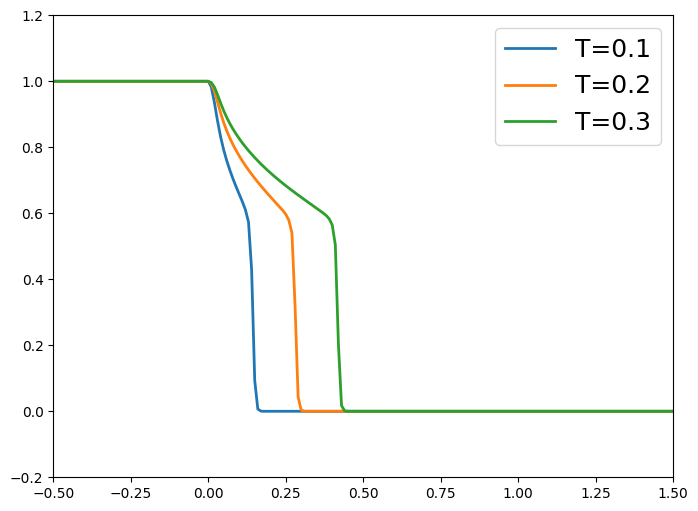

In [10]:
# plotting
fig, ax = plt.subplots(figsize=(8,6))

ax.plot(x,res[0.1],linewidth=2.0, label='T=0.1')
ax.plot(x,res[0.2],linewidth=2.0, label='T=0.2')
ax.plot(x,res[0.3],linewidth=2.0, label='T=0.3')
ax.legend(fontsize=18)
ax.set_xlim([-0.5, 1.5])
ax.set_ylim([-0.2, 1.2])
plt.show()

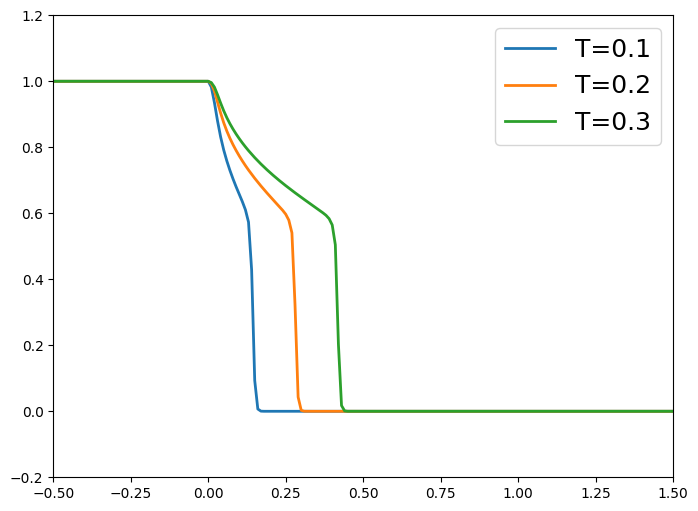

In [8]:
# plotting
fig, ax = plt.subplots(figsize=(8,6))

ax.plot(x,res[0.1],linewidth=2.0, label='T=0.1')
ax.plot(x,res[0.2],linewidth=2.0, label='T=0.2')
ax.plot(x,res[0.3],linewidth=2.0, label='T=0.3')
ax.legend(fontsize=18)
ax.set_xlim([-0.5, 1.5])
ax.set_ylim([-0.2, 1.2])
plt.show()

In [11]:
T = 0.5
n_save = 1000
n = n_save/2*3
x = np.linspace(-1, 2, n+1)
xc = (x[:-1] + x[1:]) / 2
u0 = initial(x)
u, uu = u0.copy(), u0.copy()
dx = 3 / n
t, iteration = 0, 0

times = [0]
u_save = [u0.copy()]

# loop
tau = time_step(dx,u)
while t + tau < T:
    iteration += 1
    alpha = max(abs(func_df(u)))
    t += tau
    para = max(abs(func_df(u)))
    uu = SSP_RK_WENO(u,tau,dx)
    # BL left boundary condition
    for i in range(len(x)):
        if x[i] <= 0:
            uu[i] = 1
   
    u = uu.copy()
    u_save.append(u.copy())
    times.append(t)
    tau = time_step(dx,u)
iteration += 1
tau = T - t
alpha = max(abs(func_df(u)))
t += tau
para = max(abs(func_df(u)))
uu = SSP_RK_WENO(u,tau,dx)
u = uu.copy()
u_save.append(u.copy())
times.append(t)

np.savez('data/Buckley_Leverett_ref.npz', times=np.array(times), x=x, u=np.array(u_save))

array([-1.  , -0.99, -0.98, -0.97, -0.96, -0.95, -0.94, -0.93, -0.92,
       -0.91, -0.9 , -0.89, -0.88, -0.87, -0.86, -0.85, -0.84, -0.83,
       -0.82, -0.81, -0.8 , -0.79, -0.78, -0.77, -0.76, -0.75, -0.74,
       -0.73, -0.72, -0.71, -0.7 , -0.69, -0.68, -0.67, -0.66, -0.65,
       -0.64, -0.63, -0.62, -0.61, -0.6 , -0.59, -0.58, -0.57, -0.56,
       -0.55, -0.54, -0.53, -0.52, -0.51, -0.5 , -0.49, -0.48, -0.47,
       -0.46, -0.45, -0.44, -0.43, -0.42, -0.41, -0.4 , -0.39, -0.38,
       -0.37, -0.36, -0.35, -0.34, -0.33, -0.32, -0.31, -0.3 , -0.29,
       -0.28, -0.27, -0.26, -0.25, -0.24, -0.23, -0.22, -0.21, -0.2 ,
       -0.19, -0.18, -0.17, -0.16, -0.15, -0.14, -0.13, -0.12, -0.11,
       -0.1 , -0.09, -0.08, -0.07, -0.06, -0.05, -0.04, -0.03, -0.02,
       -0.01,  0.  ,  0.01,  0.02,  0.03,  0.04,  0.05,  0.06,  0.07,
        0.08,  0.09,  0.1 ,  0.11,  0.12,  0.13,  0.14,  0.15,  0.16,
        0.17,  0.18,  0.19,  0.2 ,  0.21,  0.22,  0.23,  0.24,  0.25,
        0.26,  0.27,